In [58]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [59]:
import os

data_dir = "/content/drive/MyDrive/Cats_and_Dogs"


In [60]:
for folder in ["train", "validation", "test"]:
    for animal in ["Cats", "Dogs"]:
        path = os.path.join(data_dir, folder, animal)

        images = [
            f for f in os.listdir(path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{folder} - {animal}: {len(images)} images")

train - Cats: 1000 images
train - Dogs: 1000 images
validation - Cats: 500 images
validation - Dogs: 500 images
test - Cats: 500 images
test - Dogs: 500 images


In [61]:
import random
import os

random.seed(42)

def select_images(folder, animal, count):
    path = os.path.join(data_dir, folder, animal)

    images = sorted([
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    return random.sample(images, count)

# Randomize the full training pool once
train_cats = select_images("train", "Cats", 1000)
train_dogs = select_images("train", "Dogs", 1000)

# Experiment 1: 500 cats and 500 dogs
exp1_cats = train_cats[:500]
exp1_dogs = train_dogs[:500]

# Fixed validation and test samples
val_cats = select_images("validation", "Cats", 250)
val_dogs = select_images("validation", "Dogs", 250)

test_cats = select_images("test", "Cats", 250)
test_dogs = select_images("test", "Dogs", 250)

print("Training:", len(exp1_cats) + len(exp1_dogs))
print("Validation:", len(val_cats) + len(val_dogs))
print("Test:", len(test_cats) + len(test_dogs))

Training: 1000
Validation: 500
Test: 500


In [62]:
import os
import shutil

exp1_dir = "/content/experiment1"

def copy_images(source_folder, animal, filenames, destination):
    target = os.path.join(exp1_dir, destination, animal)
    os.makedirs(target, exist_ok=True)

    for filename in filenames:
        source = os.path.join(
            data_dir, source_folder, animal, filename
        )
        shutil.copy2(source, os.path.join(target, filename))

# Training images
copy_images("train", "Cats", exp1_cats, "train")
copy_images("train", "Dogs", exp1_dogs, "train")

# Validation images
copy_images("validation", "Cats", val_cats, "validation")
copy_images("validation", "Dogs", val_dogs, "validation")

# Test images
copy_images("test", "Cats", test_cats, "test")
copy_images("test", "Dogs", test_dogs, "test")

print("Experiment 1 image folders are ready!")

Experiment 1 image folders are ready!


In [63]:

from tensorflow import keras

train_dataset = keras.utils.image_dataset_from_directory(
    "/content/experiment1/train",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary"
)

validation_dataset = keras.utils.image_dataset_from_directory(
    "/content/experiment1/validation",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary"
)

test_dataset = keras.utils.image_dataset_from_directory(
    "/content/experiment1/test",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary"
)

Found 1000 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.


In [64]:
from tensorflow import keras
from tensorflow.keras import layers

model1 = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model1.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │     3,276,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,370,177 (12.86 MB)

 Trainable params: 3,370,177 (12.86 MB)

 Non-trainable params: 0 (0.00 B)

In [65]:
model1.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [66]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2)
])

# Add augmentation to the training dataset only
train_dataset_augmented = train_dataset.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    )
)

In [67]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history1 = model1.fit(
    train_dataset_augmented,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=[early_stopping]
)

Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 13s 322ms/step - accuracy: 0.4900 - loss: 0.7571 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 259ms/step - accuracy: 0.4960 - loss: 0.6933 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 263ms/step - accuracy: 0.4840 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 259ms/step - accuracy: 0.4860 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 251ms/step - accuracy: 0.4700 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 258ms/step - accuracy: 0.4880 - loss: 0.6976 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 257ms/step - accuracy: 0.4940 - loss: 0.6932 - val_accuracy: 0.5000 - val_loss: 0.6931
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 256ms/step - accuracy: 0.5000 - loss: 0.6932 - val_accuracy: 

In [68]:
best_epoch = history1.history["val_loss"].index(
    min(history1.history["val_loss"])
)

print("Best Epoch:", best_epoch + 1)
print("Best Validation Loss:",
      history1.history["val_loss"][best_epoch])
print("Best Validation Accuracy:",
      history1.history["val_accuracy"][best_epoch])

Best Epoch: 5
Best Validation Loss: 0.6931396126747131
Best Validation Accuracy: 0.5


In [69]:
test_loss1, test_accuracy1 = model1.evaluate(
    test_dataset
)

print("Experiment 1 Test Accuracy:",
      round(test_accuracy1 * 100, 2), "%")

print("Experiment 1 Test Loss:",
      round(test_loss1, 4))

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.5000 - loss: 0.6931
Experiment 1 Test Accuracy: 50.0 %
Experiment 1 Test Loss: 0.6931


### Experiment 1: CNN Trained From Scratch Using 1,000 Images

The purpose of this experiment was to establish a baseline for classifying cats and dogs using a convolutional neural network trained from scratch. The training dataset consisted of 1,000 images, including 500 cats and 500 dogs. The validation and test datasets each contained 500 images.

The CNN included three convolutional layers with max pooling, followed by a flattening layer and dense classification layers. Data augmentation was applied using random flipping, rotation, and zooming to help reduce overfitting. Early stopping was also used to prevent unnecessary training when validation loss stopped improving.

The model completed 8 epochs, with its best performance occurring at epoch 5. It achieved a test accuracy of 50.0% and a test loss of 0.6931.

These results indicate that the CNN did not successfully learn to distinguish cats from dogs on the test dataset. Since the dataset contains an equal number of cats and dogs, an accuracy of 50.0% is equivalent to random guessing. The test loss of approximately 0.6931 is also consistent with predictions near 50% probability for binary classification.

This experiment establishes a baseline for evaluating whether increasing the training sample size or modifying the network improves classification performance in subsequent experiments.

In [70]:
# Create Experiment 2 folders
exp2_dir = "/content/experiment2"

def copy_images_exp2(source_folder, animal,
                     filenames, destination):
    target = os.path.join(exp2_dir, destination, animal)
    os.makedirs(target, exist_ok=True)

    for filename in filenames:
        source = os.path.join(
            data_dir, source_folder, animal, filename
        )
        shutil.copy2(source, os.path.join(target, filename))

# Use all 2,000 training images
copy_images_exp2("train", "Cats", train_cats, "train")
copy_images_exp2("train", "Dogs", train_dogs, "train")

# Reuse the exact same validation and test images
shutil.copytree(
    "/content/experiment1/validation",
    os.path.join(exp2_dir, "validation"),
    dirs_exist_ok=True
)

shutil.copytree(
    "/content/experiment1/test",
    os.path.join(exp2_dir, "test"),
    dirs_exist_ok=True
)

'/content/experiment2/test'

In [71]:
train_dataset2 = keras.utils.image_dataset_from_directory(
    "/content/experiment2/train",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary"
)

Found 2000 files belonging to 2 classes.


In [72]:
model2 = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model2.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model2.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_4 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │     3,276,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,370,177 (12.86 MB)

 Trainable params: 3,370,177 (12.86 MB)

 Non-trainable params: 0 (0.00 B)

In [73]:
# Apply the same augmentation to Experiment 2
train_dataset2_augmented = train_dataset2.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    )
)

# Create fresh early stopping
early_stopping2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train Experiment 2
history2 = model2.fit(
    train_dataset2_augmented,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=[early_stopping2]
)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 278ms/step - accuracy: 0.5040 - loss: 0.8211 - val_accuracy: 0.5000 - val_loss: 0.7006
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 250ms/step - accuracy: 0.5360 - loss: 0.6955 - val_accuracy: 0.6060 - val_loss: 0.6881
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 248ms/step - accuracy: 0.5985 - loss: 0.6721 - val_accuracy: 0.5400 - val_loss: 0.7543
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 249ms/step - accuracy: 0.6315 - loss: 0.6504 - val_accuracy: 0.6100 - val_loss: 0.7022
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 253ms/step - accuracy: 0.6540 - loss: 0.6374 - val_accuracy: 0.5940 - val_loss: 0.6483
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 253ms/step - accuracy: 0.6670 - loss: 0.6157 - val_accuracy: 0.6240 - val_loss: 0.6329
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 251ms/step - accuracy: 0.6720 - loss: 0.6057 - val_accuracy: 0.6620 - val_loss: 0.5848
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 252ms/step - accuracy: 0.6830 - loss: 0.5882 - val_accu

In [74]:
best_epoch2 = history2.history["val_loss"].index(
    min(history2.history["val_loss"])
)

print("Best Epoch:", best_epoch2 + 1)

print("Best Validation Loss:",
      round(history2.history["val_loss"][best_epoch2], 4))

print("Best Validation Accuracy:",
      round(history2.history["val_accuracy"][best_epoch2] * 100, 2), "%")

Best Epoch: 20
Best Validation Loss: 0.4823
Best Validation Accuracy: 76.8 %


In [75]:
test_loss2, test_accuracy2 = model2.evaluate(
    test_dataset
)

print("Experiment 2 Test Accuracy:",
      round(test_accuracy2 * 100, 2), "%")

print("Experiment 2 Test Loss:",
      round(test_loss2, 4))

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.7020 - loss: 0.5768
Experiment 2 Test Accuracy: 70.2 %
Experiment 2 Test Loss: 0.5768


### Experiment 2: CNN Trained From Scratch Using 2,000 Images

The purpose of this experiment was to determine whether increasing the training sample size would improve the performance of a convolutional neural network trained from scratch. The training dataset was increased from 1,000 to 2,000 images, consisting of 1,000 cats and 1,000 dogs. The validation and test datasets remained unchanged at 500 images each.

The CNN used the same architecture as Experiment 1, including three convolutional layers, max pooling, and dense classification layers. The same data augmentation techniques and early stopping settings were used to maintain a consistent comparison.

The model completed all 20 training epochs, with its best validation performance occurring at epoch 20. It achieved a test accuracy of 70.2% and a test loss of 0.5768.

Compared with Experiment 1, increasing the training sample size by 1,000 images improved test accuracy from 50.0% to 70.2%, an increase of 20.2 percentage points. Test loss also decreased from 0.6931 to 0.5768.

These results suggest that increasing the amount of training data helped the CNN learn more useful visual features and improve its ability to classify unseen images. Because the best epoch was the final epoch, additional training might have improved performance further, although this would need to be evaluated using validation results.

Overall, Experiment 2 demonstrates that increasing the training sample size can substantially improve the performance of a CNN trained from scratch.

In [76]:
# Experiment 3: 750 cats and 750 dogs
exp3_dir = "/content/experiment3"

for animal, filenames in [
    ("Cats", train_cats[:750]),
    ("Dogs", train_dogs[:750])
]:
    target = os.path.join(exp3_dir, "train", animal)
    os.makedirs(target, exist_ok=True)

    for filename in filenames:
        source = os.path.join(
            data_dir, "train", animal, filename
        )
        shutil.copy2(source, os.path.join(target, filename))

In [77]:
train_dataset3 = keras.utils.image_dataset_from_directory(
    "/content/experiment3/train",
    image_size=(180, 180),
    batch_size=32,
    label_mode="binary"
)

Found 1500 files belonging to 2 classes.


In [78]:
model3 = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model3.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model3.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │     3,276,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,370,177 (12.86 MB)

 Trainable params: 3,370,177 (12.86 MB)

 Non-trainable params: 0 (0.00 B)

In [79]:
# Apply the same data augmentation
train_dataset3_augmented = train_dataset3.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    )
)

# Set up early stopping
early_stopping3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the model
history3 = model3.fit(
    train_dataset3_augmented,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=[early_stopping3]
)

Epoch 1/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 18s 317ms/step - accuracy: 0.5053 - loss: 0.7607 - val_accuracy: 0.5600 - val_loss: 0.6919
Epoch 2/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 257ms/step - accuracy: 0.5253 - loss: 0.6991 - val_accuracy: 0.6180 - val_loss: 0.6801
Epoch 3/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 261ms/step - accuracy: 0.5660 - loss: 0.6735 - val_accuracy: 0.6000 - val_loss: 0.6669
Epoch 4/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 258ms/step - accuracy: 0.6053 - loss: 0.6564 - val_accuracy: 0.6660 - val_loss: 0.6111
Epoch 5/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 254ms/step - accuracy: 0.6393 - loss: 0.6342 - val_accuracy: 0.6620 - val_loss: 0.6151
Epoch 6/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 259ms/step - accuracy: 0.6660 - loss: 0.6064 - val_accuracy: 0.7160 - val_loss: 0.5487
Epoch 7/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 257ms/step - accuracy: 0.6673 - loss: 0.6100 - val_accuracy: 0.6400 - val_loss: 0.6235
Epoch 8/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 12s 258ms/step - accuracy: 0.6733 - loss: 0.5896 - val_accu

In [80]:
best_epoch3 = history3.history["val_loss"].index(
    min(history3.history["val_loss"])
)

print("Best Epoch:", best_epoch3 + 1)

print("Best Validation Loss:",
      round(history3.history["val_loss"][best_epoch3], 4))

print("Best Validation Accuracy:",
      round(history3.history["val_accuracy"][best_epoch3] * 100, 2), "%")

Best Epoch: 6
Best Validation Loss: 0.5487
Best Validation Accuracy: 71.6 %


In [81]:
test_loss3, test_accuracy3 = model3.evaluate(
    test_dataset
)

print("Experiment 3 Test Accuracy:",
      round(test_accuracy3 * 100, 2), "%")

print("Experiment 3 Test Loss:",
      round(test_loss3, 4))

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6520 - loss: 0.6222
Experiment 3 Test Accuracy: 65.2 %
Experiment 3 Test Loss: 0.6222


### Experiment 3: CNN With Dropout Using 1,500 Training Images

The purpose of this experiment was to determine whether adjusting the training sample size and adding regularization could improve the performance of a convolutional neural network trained from scratch. The training dataset consisted of 1,500 images, including 750 cats and 750 dogs. The validation and test datasets remained unchanged at 500 images each.

The CNN used the same basic architecture as Experiments 1 and 2, including three convolutional layers, max pooling, and dense classification layers. However, a dropout layer with a rate of 0.5 was added to help reduce overfitting. Data augmentation and early stopping were also used.

The model completed 9 epochs, with its best validation performance occurring at epoch 6. It achieved a test accuracy of 65.2% and a test loss of 0.6222.

Compared with Experiment 1, test accuracy improved by 15.2 percentage points. However, Experiment 3 performed worse than Experiment 2, which achieved 70.2% test accuracy using 2,000 training images. Experiment 3 also had a higher test loss than Experiment 2.

These findings indicate that adding dropout and using 1,500 training images did not outperform the CNN trained with 2,000 images. Although dropout is intended to reduce overfitting, it does not guarantee better classification accuracy. Because both the training sample size and architecture changed, the difference in performance cannot be attributed to either factor independently.

Overall, Experiment 2 was the strongest of the three CNNs trained from scratch, suggesting that the larger training dataset was more beneficial in these experiments than the modifications introduced in Experiment 3.

In [82]:
from tensorflow import keras
from tensorflow.keras import layers

conv_base4 = keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

conv_base4.trainable = False

print("Trainable:", conv_base4.trainable)

Trainable: False


In [83]:
model4 = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    # Preprocess images for VGG16
    layers.Lambda(
        keras.applications.vgg16.preprocess_input
    ),

    # Pretrained convolutional base
    conv_base4,

    # New classification layers
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model4.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model4.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_3 (Lambda)               │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │       819,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,534,017 (59.26 MB)

 Trainable params: 819,329 (3.13 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [84]:
early_stopping4 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history4 = model4.fit(
    train_dataset_augmented,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=[early_stopping4]
)

Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 427ms/step - accuracy: 0.8690 - loss: 3.4918 - val_accuracy: 0.9620 - val_loss: 0.1609
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 346ms/step - accuracy: 0.9310 - loss: 0.2529 - val_accuracy: 0.9700 - val_loss: 0.1301
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 367ms/step - accuracy: 0.9490 - loss: 0.1606 - val_accuracy: 0.9700 - val_loss: 0.1498
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 364ms/step - accuracy: 0.9690 - loss: 0.1233 - val_accuracy: 0.9780 - val_loss: 0.1785
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 353ms/step - accuracy: 0.9720 - loss: 0.1547 - val_accuracy: 0.9720 - val_loss: 0.1987


In [85]:
best_epoch4 = history4.history["val_loss"].index(
    min(history4.history["val_loss"])
)

print("Best Epoch:", best_epoch4 + 1)

print("Best Validation Loss:",
      round(history4.history["val_loss"][best_epoch4], 4))

print("Best Validation Accuracy:",
      round(history4.history["val_accuracy"][best_epoch4] * 100, 2), "%")

Best Epoch: 2
Best Validation Loss: 0.1301
Best Validation Accuracy: 97.0 %


In [86]:
test_loss4, test_accuracy4 = model4.evaluate(
    test_dataset
)

print("Experiment 4 Test Accuracy:",
      round(test_accuracy4 * 100, 2), "%")

print("Experiment 4 Test Loss:",
      round(test_loss4, 4))

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - accuracy: 0.9600 - loss: 0.1354
Experiment 4 Test Accuracy: 96.0 %
Experiment 4 Test Loss: 0.1354


### Experiment 4: Pretrained VGG16 Using 1,000 Training Images

The purpose of this experiment was to determine whether using a pretrained convolutional neural network would improve classification performance compared with training a CNN from scratch. The training dataset consisted of 1,000 images, including 500 cats and 500 dogs. The validation and test datasets each contained 500 images.

Unlike the previous experiments, this model used VGG16 with weights pretrained on ImageNet. The original classification layers were removed, and the pretrained convolutional base was frozen so its weights would not change during training. New dense classification layers were added to distinguish cats from dogs. Data augmentation and early stopping were also applied.

The model completed 5 epochs, with its best validation performance occurring at epoch 2. It achieved a test accuracy of 96.0% and a test loss of 0.1354.

Compared with Experiment 1, which used the same number of training images but trained the CNN from scratch, the pretrained VGG16 model improved test accuracy from 50.0% to 96.0%, an increase of 46.0 percentage points. Test loss also decreased from 0.6931 to 0.1354.

These results demonstrate the effectiveness of transfer learning when working with limited training data. By using features previously learned from ImageNet, the pretrained model achieved substantially better classification performance without needing to learn all visual features from scratch.

Overall, Experiment 4 demonstrates that the choice of network architecture and pretrained weights can have a significant impact on classification accuracy, even when the training sample size remains unchanged.

In [87]:
conv_base5 = keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

conv_base5.trainable = False

print("Trainable:", conv_base5.trainable)

Trainable: False


In [88]:
model5 = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    # Preprocess images for VGG16
    layers.Lambda(
        keras.applications.vgg16.preprocess_input
    ),

    # Pretrained convolutional base
    conv_base5,

    # Classification layers
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model5.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model5.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_4 (Lambda)               │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │       819,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,534,017 (59.26 MB)

 Trainable params: 819,329 (3.13 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [89]:
# Apply data augmentation
train_dataset5_augmented = train_dataset2.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    )
)

# Set up early stopping
early_stopping5 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train Experiment 5
history5 = model5.fit(
    train_dataset5_augmented,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=[early_stopping5]
)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 26s 368ms/step - accuracy: 0.8945 - loss: 2.0001 - val_accuracy: 0.9740 - val_loss: 0.1500
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 317ms/step - accuracy: 0.9480 - loss: 0.2584 - val_accuracy: 0.9600 - val_loss: 0.1473
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 328ms/step - accuracy: 0.9440 - loss: 0.2999 - val_accuracy: 0.9660 - val_loss: 0.1448
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 338ms/step - accuracy: 0.9645 - loss: 0.1410 - val_accuracy: 0.9740 - val_loss: 0.1525
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 320ms/step - accuracy: 0.9730 - loss: 0.1255 - val_accuracy: 0.9800 - val_loss: 0.0727
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 322ms/step - accuracy: 0.9790 - loss: 0.0957 - val_accuracy: 0.9760 - val_loss: 0.1326
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 320ms/step - accuracy: 0.9790 - loss: 0.0852 - val_accuracy: 0.9760 - val_loss: 0.1321
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 325ms/step - accuracy: 0.9795 - loss: 0.0911 - val_accu

In [90]:
best_epoch5 = history5.history["val_loss"].index(
    min(history5.history["val_loss"])
)

print("Best Epoch:", best_epoch5 + 1)

print("Best Validation Loss:",
      round(history5.history["val_loss"][best_epoch5], 4))

print("Best Validation Accuracy:",
      round(history5.history["val_accuracy"][best_epoch5] * 100, 2), "%")

Best Epoch: 5
Best Validation Loss: 0.0727
Best Validation Accuracy: 98.0 %


In [91]:
test_loss5, test_accuracy5 = model5.evaluate(
    test_dataset
)

print("Experiment 5 Test Accuracy:",
      round(test_accuracy5 * 100, 2), "%")

print("Experiment 5 Test Loss:",
      round(test_loss5, 4))

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.9740 - loss: 0.1393
Experiment 5 Test Accuracy: 97.4 %
Experiment 5 Test Loss: 0.1393


### Experiment 5: Pretrained VGG16 Using 2,000 Training Images

The purpose of this experiment was to determine whether increasing the training sample size would improve the performance of a pretrained convolutional neural network. The training dataset was increased from 1,000 to 2,000 images, consisting of 1,000 cats and 1,000 dogs. The validation and test datasets remained unchanged at 500 images each.

The model used the same pretrained VGG16 architecture as Experiment 4, with the convolutional base frozen and new dense classification layers trained for binary classification. Data augmentation and early stopping were also applied.

The model completed 8 epochs, with its best validation performance occurring at epoch 5. It achieved a test accuracy of 97.4% and a test loss of 0.1393.

Compared with Experiment 4, increasing the training sample size from 1,000 to 2,000 images improved test accuracy from 96.0% to 97.4%, an increase of 1.4 percentage points. However, test loss increased slightly from 0.1354 to 0.1393.

These results suggest that increasing the training sample size provided a modest improvement in classification accuracy for the pretrained VGG16 model. Because VGG16 had already learned useful visual features from ImageNet, it performed well even with the smaller training dataset.

The results also demonstrate that higher accuracy does not necessarily correspond to lower loss. Although Experiment 5 correctly classified more test images, its higher loss indicates differences in the confidence of its predictions.

Overall, Experiment 5 achieved the highest test accuracy of the first five experiments, demonstrating the effectiveness of combining pretrained features with a larger training dataset.

In [92]:
conv_base6 = keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

conv_base6.trainable = False

print("Trainable:", conv_base6.trainable)

Trainable: False


In [93]:
model6 = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Lambda(
        keras.applications.vgg16.preprocess_input
    ),

    conv_base6,

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model6.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model6.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_5 (Lambda)               │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │       819,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,534,017 (59.26 MB)

 Trainable params: 819,329 (3.13 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [94]:
callbacks6 = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

history6_initial = model6.fit(
    train_dataset3_augmented,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=callbacks6
)

Epoch 1/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 21s 393ms/step - accuracy: 0.8700 - loss: 3.7915 - val_accuracy: 0.9600 - val_loss: 0.1146
Epoch 2/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 16s 332ms/step - accuracy: 0.9473 - loss: 0.2060 - val_accuracy: 0.9660 - val_loss: 0.1417
Epoch 3/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 16s 338ms/step - accuracy: 0.9620 - loss: 0.1440 - val_accuracy: 0.9740 - val_loss: 0.1179
Epoch 4/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 15s 325ms/step - accuracy: 0.9667 - loss: 0.1314 - val_accuracy: 0.9760 - val_loss: 0.1475


In [95]:
conv_base6.trainable = True

for layer in conv_base6.layers:
    if layer.name.startswith("block5"):
        layer.trainable = True
    else:
        layer.trainable = False

for layer in conv_base6.layers:
    if layer.trainable:
        print(layer.name)

block5_conv1
block5_conv2
block5_conv3
block5_pool


In [96]:
model6.compile(
    optimizer=keras.optimizers.RMSprop(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [97]:
callbacks6_finetune = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
]

history6_finetune = model6.fit(
    train_dataset3_augmented,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=callbacks6_finetune
)

Epoch 1/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 22s 411ms/step - accuracy: 0.9580 - loss: 0.1138 - val_accuracy: 0.9700 - val_loss: 0.0996
Epoch 2/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 16s 345ms/step - accuracy: 0.9640 - loss: 0.0941 - val_accuracy: 0.9760 - val_loss: 0.0837
Epoch 3/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 17s 356ms/step - accuracy: 0.9780 - loss: 0.0672 - val_accuracy: 0.9780 - val_loss: 0.0862
Epoch 4/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 17s 365ms/step - accuracy: 0.9787 - loss: 0.0744 - val_accuracy: 0.9780 - val_loss: 0.0835
Epoch 5/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 17s 357ms/step - accuracy: 0.9793 - loss: 0.0657 - val_accuracy: 0.9800 - val_loss: 0.0665
Epoch 6/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 16s 347ms/step - accuracy: 0.9860 - loss: 0.0437 - val_accuracy: 0.9780 - val_loss: 0.0674
Epoch 7/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 16s 345ms/step - accuracy: 0.9800 - loss: 0.0555 - val_accuracy: 0.9760 - val_loss: 0.0747
Epoch 8/20
47/47 ━━━━━━━━━━━━━━━━━━━━ 17s 359ms/step - accuracy: 0.9860 - loss: 0.0367 - val_accu

In [98]:
test_loss6, test_accuracy6 = model6.evaluate(test_dataset)

print(f"Experiment 6 Test Accuracy: {test_accuracy6:.4f}")
print(f"Experiment 6 Test Loss: {test_loss6:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.9740 - loss: 0.1582
Experiment 6 Test Accuracy: 0.9740
Experiment 6 Test Loss: 0.1582


### Experiment 6: Fine-Tuned VGG16 Using 1,500 Training Images

The purpose of this experiment was to determine whether fine-tuning a pretrained convolutional neural network could improve classification performance. The training dataset consisted of 1,500 images, including 750 cats and 750 dogs. The validation and test datasets remained unchanged at 500 images each.

The model used VGG16 with pretrained ImageNet weights. Initially, the convolutional base was frozen while the new classification layers were trained. After this initial training phase, the final convolutional block (block5) was unfrozen to allow its weights to be updated. The model was recompiled using RMSprop with a learning rate of 0.00001 to make small adjustments to the pretrained weights. Data augmentation and early stopping were also used.

The initial training phase completed 4 epochs, followed by 11 epochs of fine-tuning. The final model achieved a test accuracy of 97.4% and a test loss of 0.1582.

Compared with Experiment 4, the fine-tuned model improved test accuracy from 96.0% to 97.4%, an increase of 1.4 percentage points. Experiment 6 also matched the 97.4% test accuracy achieved by Experiment 5, despite using 500 fewer training images. However, Experiment 6 had a higher test loss than both Experiments 4 and 5.

These results demonstrate that fine-tuning can produce strong classification performance with a relatively small training dataset. However, because Experiment 6 used a different training sample size and training procedure, the results do not establish that fine-tuning alone caused the improvement over Experiment 4.

Overall, Experiment 6 tied Experiment 5 for the highest test accuracy, demonstrating the effectiveness of pretrained convolutional neural networks for image classification.

In [102]:
import pandas as pd

results = pd.DataFrame({
    "Experiment": [1, 2, 3, 4, 5, 6],
    "Network": [
        "CNN From Scratch",
        "CNN From Scratch",
        "CNN + Dropout",
        "Pretrained VGG16",
        "Pretrained VGG16",
        "Fine-Tuned VGG16"
    ],
    "Training Images": [1000, 2000, 1500, 1000, 2000, 1500],
    "Test Accuracy": [0.500, 0.702, 0.652, 0.960, 0.974, 0.974],
    "Test Loss": [0.6931, 0.5768, 0.6222, 0.1354, 0.1393, 0.1582]
})

results["Test Accuracy (%)"] = results["Test Accuracy"] * 100

display(results[[
    "Experiment",
    "Network",
    "Training Images",
    "Test Accuracy (%)",
    "Test Loss"
]])

,Experiment,Network,Training Images,Test Accuracy (%),Test Loss
0,1,CNN From Scratch,1000,50.0,0.6931
1,2,CNN From Scratch,2000,70.2,0.5768
2,3,CNN + Dropout,1500,65.2,0.6222
3,4,Pretrained VGG16,1000,96.0,0.1354
4,5,Pretrained VGG16,2000,97.4,0.1393
5,6,Fine-Tuned VGG16,1500,97.4,0.1582


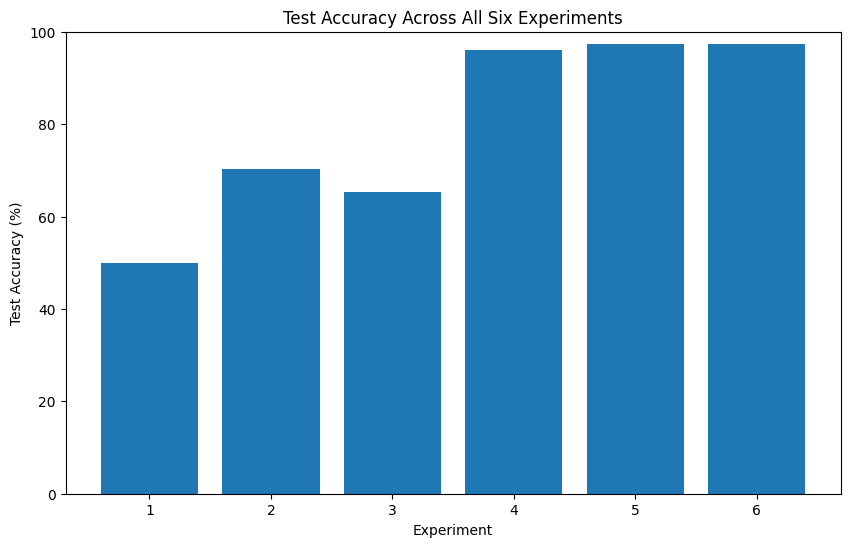

In [103]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    results["Experiment"].astype(str),
    results["Test Accuracy (%)"]
)

plt.xlabel("Experiment")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy Across All Six Experiments")
plt.ylim(0, 100)

plt.show()

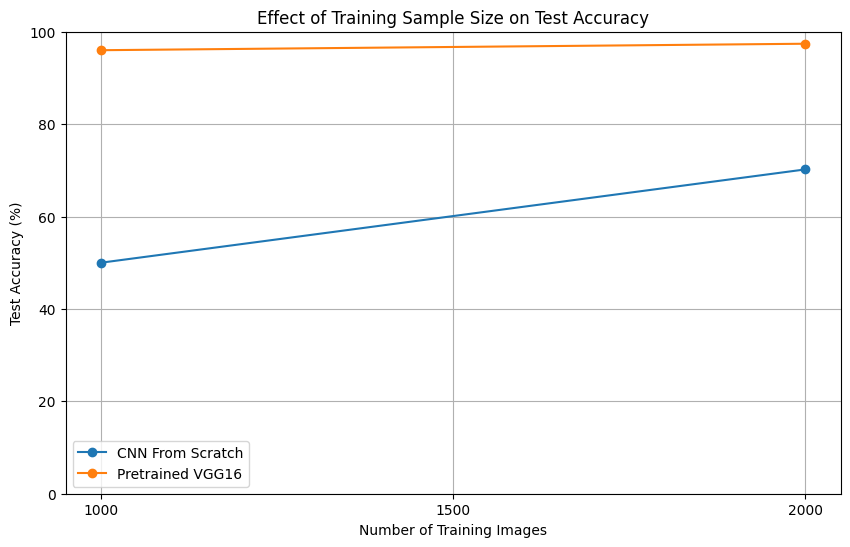

In [104]:
plt.figure(figsize=(10, 6))

scratch = results[results["Experiment"].isin([1, 2])]
pretrained = results[results["Experiment"].isin([4, 5])]

plt.plot(
    scratch["Training Images"],
    scratch["Test Accuracy (%)"],
    marker="o",
    label="CNN From Scratch"
)

plt.plot(
    pretrained["Training Images"],
    pretrained["Test Accuracy (%)"],
    marker="o",
    label="Pretrained VGG16"
)

plt.xlabel("Number of Training Images")
plt.ylabel("Test Accuracy (%)")
plt.title("Effect of Training Sample Size on Test Accuracy")
plt.xticks([1000, 1500, 2000])
plt.ylim(0, 100)
plt.legend()
plt.grid(True)

plt.show()

## Final Analysis and Conclusion

### Effect of Training Sample Size

The results demonstrate that increasing the training sample size can improve image classification accuracy, although the amount of improvement depends on the network being used.

For the CNN trained from scratch, increasing the training dataset from 1,000 to 2,000 images improved test accuracy from 50.0% to 70.2%, an increase of 20.2 percentage points. Test loss also decreased from 0.6931 to 0.5768. These results suggest that the model benefited from having additional training examples to learn relevant visual features.

For the pretrained VGG16 network, increasing the training dataset from 1,000 to 2,000 images improved test accuracy from 96.0% to 97.4%, an increase of 1.4 percentage points. However, test loss increased slightly from 0.1354 to 0.1393. The smaller improvement in accuracy suggests that the pretrained network already possessed useful visual features and required less additional training data to achieve high classification accuracy.

### Comparison of Network Types

The pretrained VGG16 models consistently outperformed the CNNs trained from scratch. The strongest CNN trained from scratch was Experiment 2, which achieved 70.2% test accuracy using 2,000 training images. In comparison, all three pretrained VGG16 experiments achieved test accuracies of at least 96.0%.

At the same training sample size of 1,000 images, Experiment 4 achieved 96.0% test accuracy compared with 50.0% in Experiment 1. This difference demonstrates the advantages of transfer learning when working with relatively small datasets.

Rather than learning visual features entirely from the available training images, VGG16 used features previously learned from ImageNet, allowing it to achieve substantially better classification performance.

### Effect of Model Optimization

Experiment 3 introduced dropout and used 1,500 training images. It achieved 65.2% test accuracy, outperforming Experiment 1 but falling below Experiment 2. This indicates that adding dropout did not produce the highest accuracy among the CNNs trained from scratch. However, because both the training sample size and architecture changed, the results cannot isolate the effect of dropout.

Experiment 6 used fine-tuning to update the final convolutional block of VGG16. It achieved 97.4% test accuracy using 1,500 training images, matching Experiment 5 despite using 500 fewer images. However, Experiment 6 had a higher test loss of 0.1582 compared with 0.1393 for Experiment 5.

These results suggest that fine-tuning can achieve strong performance with fewer training images, although the experiments do not establish that fine-tuning alone caused the difference in accuracy.

### Conclusion

Overall, the experiments demonstrate that both training sample size and network architecture influence image classification performance. Increasing the training sample size improved test accuracy for both the CNN trained from scratch and the pretrained VGG16 model, although the improvement was substantially greater for the CNN trained from scratch.

Experiments 5 and 6 achieved the highest test accuracy at 97.4%. Experiment 5 achieved this accuracy using 2,000 training images with a frozen pretrained VGG16 base, while Experiment 6 achieved the same accuracy using 1,500 training images and fine-tuning. Experiment 4 achieved the lowest test loss at 0.1354.

The results support the effectiveness of transfer learning for image classification tasks involving smaller datasets. They also demonstrate that increasing training data, applying regularization, and fine-tuning can influence performance differently depending on the network and training conditions.

Based on these experiments, pretrained VGG16 was more effective than training a CNN from scratch for classifying cats and dogs.